# Day 4: Colour images, data augmentation and CIFAR-10

**Goal:** train the same CNN on CIFAR-10 (a) without augmentation, (b) with augmentation (random crop + horizontal flip), and (c) optionally with augmentation + a learning-rate scheduler, then compare them.

**Why CIFAR-10 is harder than Fashion-MNIST**
- Images are 32x32 **colour** (3 channels, so input shape is `3x32x32`, not `1x28x28`).
- Classes (planes, cars, birds, cats, deer, dogs, frogs, horses, ships, trucks) look similar to each other, and objects vary a lot in position, scale, lighting and background.
- Fashion-MNIST is centred grayscale clothing on a plain background, so a small CNN gets ~90%+; the same small CNN gets far less on CIFAR-10.

**Rules followed in this notebook**
- Augmentation is applied to the **training set only**. Validation and test sets only get `ToTensor` + `Normalize`.
- The 50,000 training images are split into 45,000 train / 5,000 validation (same split for every experiment). The 10,000 test images are used once per experiment at the end.
- Same model, optimizer, epochs and seed in every experiment, so the only difference is what we change.

In [1]:
import time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)   # In Colab: Runtime > Change runtime type > GPU

Using device: cuda


In [2]:
BATCH_SIZE = 128
EPOCHS     = 20
LR         = 1e-3
VAL_SIZE   = 5000

CLASSES = ("plane","car","bird","cat","deer","dog","frog","horse","ship","truck")
MEAN = (0.4914, 0.4822, 0.4465)   # per-channel (R,G,B) statistics of CIFAR-10 train set
STD  = (0.2470, 0.2435, 0.2616)

## 1. Data and transforms

In [3]:
# Used for validation + test (and for the no-augmentation run): NO randomness
plain_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

# Used for the training set in the augmentation runs
aug_tf = T.Compose([
    T.RandomCrop(32, padding=4),      # pad 4 px, then crop a random 32x32 window
    T.RandomHorizontalFlip(p=0.5),
    # T.RandomRotation(10),           # optional: small rotations
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

root = "./data"
train_plain = torchvision.datasets.CIFAR10(root, train=True,  download=True,  transform=plain_tf)
train_aug   = torchvision.datasets.CIFAR10(root, train=True,  download=False, transform=aug_tf)
test_set    = torchvision.datasets.CIFAR10(root, train=False, download=True,  transform=plain_tf)

# Fixed train/val split of indices, shared by every experiment
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(train_plain), generator=g).tolist()
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

# Validation ALWAYS uses plain_tf (no augmentation)
val_set = Subset(train_plain, val_idx)

def make_loaders(use_aug):
    tr = Subset(train_aug if use_aug else train_plain, train_idx)
    train_loader = DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
    val_loader   = DataLoader(val_set, batch_size=256, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)
    return train_loader, val_loader, test_loader

print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_set)}")
x, y = train_plain[0]
print("One image tensor shape (channels, H, W):", tuple(x.shape))

100%|██████████| 170M/170M [27:27<00:00, 104kB/s] 


train 45000 | val 5000 | test 10000
One image tensor shape (channels, H, W): (3, 32, 32)


### What does augmentation actually do?
The top row is the original image; the other rows are random augmented versions of it.

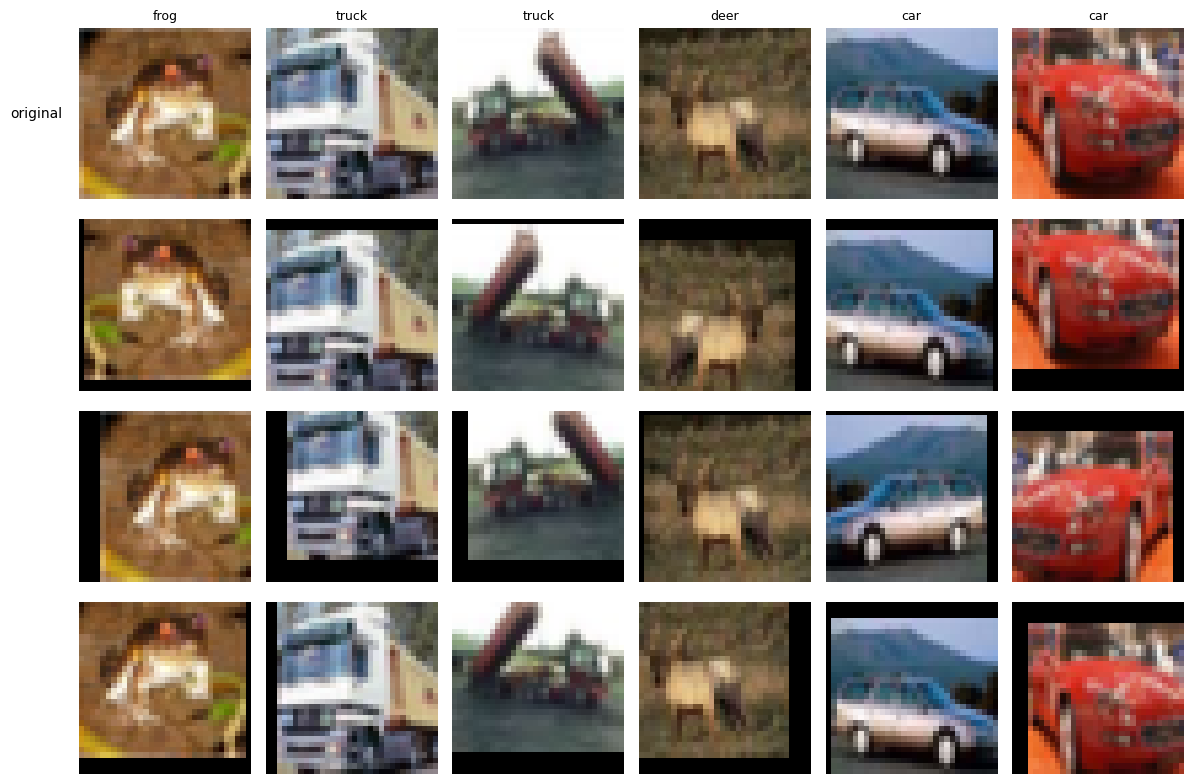

In [4]:
raw = torchvision.datasets.CIFAR10(root, train=True, download=False, transform=None)  # PIL images
viz_aug = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()])

n_img, n_var = 6, 3
fig, axes = plt.subplots(n_var + 1, n_img, figsize=(n_img * 2, (n_var + 1) * 2))
for j in range(n_img):
    img, label = raw[j]
    axes[0, j].imshow(img); axes[0, j].set_title(CLASSES[label], fontsize=9)
    for i in range(1, n_var + 1):
        axes[i, j].imshow(viz_aug(img))
for ax in axes.ravel(): ax.axis("off")
axes[0, 0].text(-0.1, 0.5, "original", transform=axes[0,0].transAxes, ha="right", va="center")
plt.tight_layout(); plt.show()

## 2. Model
A small VGG-style CNN: three blocks of (conv-BN-ReLU) x2 + max-pool, then a classifier. No dropout on purpose, so overfitting is easy to see.

In [5]:
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))  # 32 -> 16 -> 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

print(CNN())
print("Parameters:", sum(p.numel() for p in CNN().parameters()))

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, pa

## 3. Training and evaluation helpers

In [6]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct    += (out.argmax(1) == yb).sum().item()
            n          += xb.size(0)
    return total_loss / n, correct / n

def run_experiment(name, use_aug, use_scheduler=False):
    set_seed()                                   # same init + same data order logic for every run
    train_loader, val_loader, test_loader = make_loaders(use_aug)
    model = CNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS) if use_scheduler else None

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, best_state = 0.0, None
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, train_loader, optimizer)
        vl, va = run_epoch(model, val_loader)
        if scheduler: scheduler.step()
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        if va > best_val:
            best_val, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {epoch:2d}/{EPOCHS} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    model.load_state_dict(best_state)            # test the best-validation checkpoint
    _, test_acc = run_epoch(model, test_loader)
    print(f"[{name}] done in {time.time()-t0:.0f}s | best val acc {best_val:.3f} | TEST acc {test_acc:.3f}")
    return {"name": name, "hist": hist, "best_val": best_val, "test_acc": test_acc}

results = []

## 4. Experiment A: no augmentation (baseline)

In [7]:
results.append(run_experiment('No augmentation', use_aug=False))

[No augmentation] epoch  1/20 | train loss 1.248 acc 0.546 | val loss 0.937 acc 0.659
[No augmentation] epoch  2/20 | train loss 0.766 acc 0.728 | val loss 0.721 acc 0.745
[No augmentation] epoch  3/20 | train loss 0.605 acc 0.787 | val loss 0.610 acc 0.784
[No augmentation] epoch  4/20 | train loss 0.499 acc 0.826 | val loss 0.671 acc 0.770
[No augmentation] epoch  5/20 | train loss 0.417 acc 0.854 | val loss 0.687 acc 0.777
[No augmentation] epoch  6/20 | train loss 0.343 acc 0.880 | val loss 0.655 acc 0.791
[No augmentation] epoch  7/20 | train loss 0.286 acc 0.901 | val loss 0.602 acc 0.811
[No augmentation] epoch  8/20 | train loss 0.231 acc 0.920 | val loss 0.618 acc 0.811
[No augmentation] epoch  9/20 | train loss 0.182 acc 0.936 | val loss 0.707 acc 0.795
[No augmentation] epoch 10/20 | train loss 0.144 acc 0.949 | val loss 0.723 acc 0.801
[No augmentation] epoch 11/20 | train loss 0.116 acc 0.960 | val loss 0.712 acc 0.816
[No augmentation] epoch 12/20 | train loss 0.097 acc 0

## 5. Experiment B: with augmentation (RandomCrop + RandomHorizontalFlip)

In [8]:
results.append(run_experiment('Augmentation', use_aug=True))

[Augmentation] epoch  1/20 | train loss 1.401 acc 0.488 | val loss 1.259 acc 0.564
[Augmentation] epoch  2/20 | train loss 0.934 acc 0.668 | val loss 0.806 acc 0.718
[Augmentation] epoch  3/20 | train loss 0.774 acc 0.727 | val loss 0.672 acc 0.768
[Augmentation] epoch  4/20 | train loss 0.675 acc 0.763 | val loss 0.697 acc 0.762
[Augmentation] epoch  5/20 | train loss 0.620 acc 0.783 | val loss 0.637 acc 0.787
[Augmentation] epoch  6/20 | train loss 0.566 acc 0.802 | val loss 0.582 acc 0.803
[Augmentation] epoch  7/20 | train loss 0.533 acc 0.813 | val loss 0.574 acc 0.805
[Augmentation] epoch  8/20 | train loss 0.502 acc 0.825 | val loss 0.574 acc 0.804
[Augmentation] epoch  9/20 | train loss 0.469 acc 0.837 | val loss 0.512 acc 0.829
[Augmentation] epoch 10/20 | train loss 0.446 acc 0.844 | val loss 0.465 acc 0.843
[Augmentation] epoch 11/20 | train loss 0.424 acc 0.852 | val loss 0.469 acc 0.845
[Augmentation] epoch 12/20 | train loss 0.410 acc 0.858 | val loss 0.544 acc 0.822
[Aug

## 6. Experiment C (optional): augmentation + cosine learning-rate scheduler

In [9]:
results.append(run_experiment('Aug + LR scheduler', use_aug=True, use_scheduler=True))

[Aug + LR scheduler] epoch  1/20 | train loss 1.400 acc 0.489 | val loss 1.210 acc 0.577
[Aug + LR scheduler] epoch  2/20 | train loss 0.937 acc 0.667 | val loss 0.769 acc 0.733
[Aug + LR scheduler] epoch  3/20 | train loss 0.776 acc 0.725 | val loss 0.651 acc 0.776
[Aug + LR scheduler] epoch  4/20 | train loss 0.672 acc 0.763 | val loss 0.721 acc 0.751
[Aug + LR scheduler] epoch  5/20 | train loss 0.612 acc 0.788 | val loss 0.649 acc 0.779
[Aug + LR scheduler] epoch  6/20 | train loss 0.557 acc 0.806 | val loss 0.621 acc 0.789
[Aug + LR scheduler] epoch  7/20 | train loss 0.516 acc 0.819 | val loss 0.560 acc 0.807
[Aug + LR scheduler] epoch  8/20 | train loss 0.475 acc 0.835 | val loss 0.556 acc 0.812
[Aug + LR scheduler] epoch  9/20 | train loss 0.447 acc 0.845 | val loss 0.491 acc 0.835
[Aug + LR scheduler] epoch 10/20 | train loss 0.414 acc 0.857 | val loss 0.454 acc 0.845
[Aug + LR scheduler] epoch 11/20 | train loss 0.383 acc 0.866 | val loss 0.442 acc 0.852
[Aug + LR scheduler] 

## 7. Learning curves

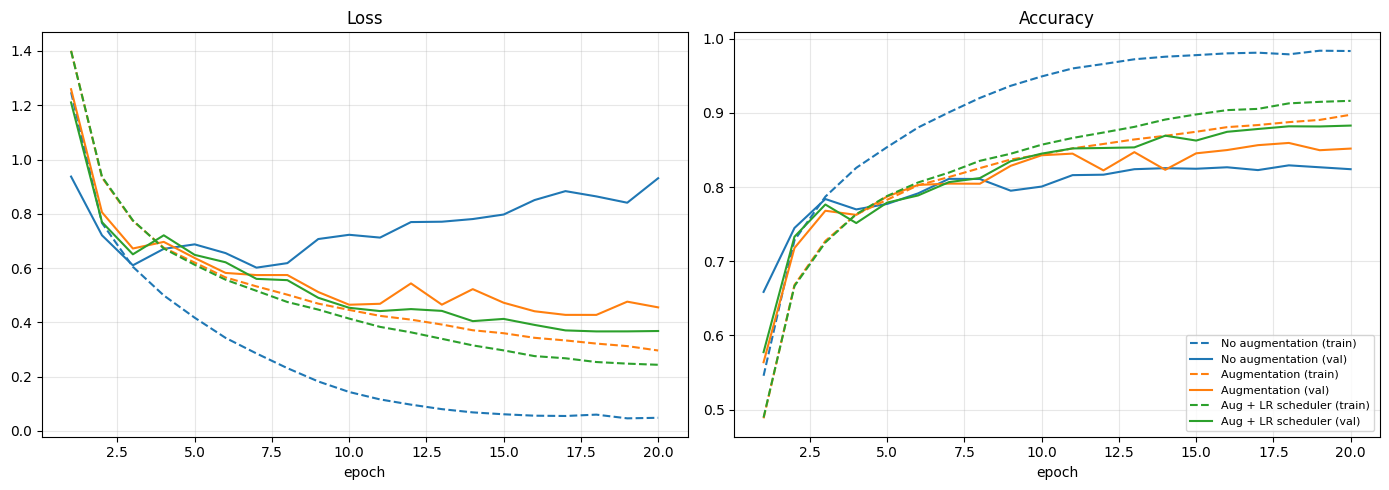

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for r, c in zip(results, colors):
    ep = range(1, EPOCHS + 1)
    axes[0].plot(ep, r["hist"]["train_loss"], "--", color=c, label=f"{r['name']} (train)")
    axes[0].plot(ep, r["hist"]["val_loss"],   "-",  color=c, label=f"{r['name']} (val)")
    axes[1].plot(ep, r["hist"]["train_acc"],  "--", color=c, label=f"{r['name']} (train)")
    axes[1].plot(ep, r["hist"]["val_acc"],    "-",  color=c, label=f"{r['name']} (val)")
axes[0].set_title("Loss"); axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("cifar10_curves.png", dpi=150); plt.show()

## 8. Comparison table
*Overfitting gap* = final train accuracy minus final validation accuracy (a big positive gap = overfitting).
Note: with augmentation the train accuracy is measured on augmented (harder) images, so it is naturally lower.

In [11]:
rows = []
for r in results:
    h = r["hist"]
    rows.append({
        "Experiment": r["name"],
        "Final train acc (%)": 100 * h["train_acc"][-1],
        "Final val acc (%)":   100 * h["val_acc"][-1],
        "Overfit gap (train - val, pts)": 100 * (h["train_acc"][-1] - h["val_acc"][-1]),
        "Final val loss": h["val_loss"][-1],
        "Best val acc (%)": 100 * r["best_val"],
        "Test acc (%)": 100 * r["test_acc"],
    })
table = pd.DataFrame(rows).set_index("Experiment").round(2)
table.to_csv("cifar10_comparison.csv")
table

,Final train acc (%),Final val acc (%),"Overfit gap (train - val, pts)",Final val loss,Best val acc (%),Test acc (%)
Experiment,,,,,,
No augmentation,98.33,82.40,15.93,0.93,82.92,82.54
Augmentation,89.74,85.18,4.56,0.46,85.94,85.14
Aug + LR scheduler,91.62,88.28,3.34,0.37,88.28,87.02
